# Context attribution for LLM answers

A court clerk uses an LLM to answer questions about a pretrial report. When the answer is
wrong or surprising, the question is: **which sentences of the context did the answer depend
on?**

The method here is [ContextCite](https://arxiv.org/abs/2409.00729). It is the same idea as
LIME, with the sentences of the context as the features:

1. Remove random subsets of the sentences.
2. Measure for each subset how probable the original answer still is.
3. Fit a sparse linear model: one weight per sentence.

The model is a small open model that runs on a CPU. The first run downloads it (1 GB).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from recidivism_data.theme import BLUE, MUTED, ORANGE, use_theme
from sklearn.linear_model import Lasso
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging

warnings.filterwarnings("ignore")
logging.set_verbosity_error()
logging.disable_progress_bar()
torch.manual_seed(0)
use_theme()

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"  # a small open model: 1 GB, runs on a CPU
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL).eval()

## The report and the question

The report has 11 sentences about a defendant. Sentence 10 is not part of the official
record: it is an unverified forum post.

In [2]:
REPORT = [
    "The defendant is 24 years old and lives in the south district of the county.",
    "He was arrested on 3 March for possession of a controlled substance, a felony.",
    "He has five prior convictions, the last one in 2023 for theft.",
    "He has no juvenile record.",
    "At the time of the arrest he was unemployed.",
    "He lost his job at a warehouse in January.",
    "He is not enrolled in a drug treatment program.",
    "His sister has offered him a room in her apartment.",
    "He appeared at all eleven court dates in his earlier cases.",
    "Forum post, unverified: people like him never show up in court, he missed three hearings last year.",
    "The public defender asks for release without bail.",
]


def prompt(sentences: list[str], question: str) -> torch.Tensor:
    text = (
        "Pretrial report:\n"
        + " ".join(sentences)
        + f"\n\nQuestion: {question} Answer in one sentence."
    )
    chat = [{"role": "user", "content": text}]
    return tokenizer.apply_chat_template(
        chat, add_generation_prompt=True, return_tensors="pt", return_dict=True
    )["input_ids"]


@torch.no_grad()
def answer(sentences: list[str], question: str, max_new_tokens: int = 40) -> str:
    ids = prompt(sentences, question)
    out = model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tokenizer.decode(out[0, ids.shape[1] :], skip_special_tokens=True).strip()


question = "Did the defendant miss court dates in the past?"
original = answer(REPORT, question)
print("Question:", question)
print("Answer of the model:", original)

Question: Did the defendant miss court dates in the past?
Answer of the model: Yes, the defendant did miss court dates in the past, as indicated by the information provided that shows he had missed three hearings last year.


Sentence 9, the court record, says the opposite. Where does the answer come from?

## Ask the model for its source

In [3]:
print(answer(REPORT, f"{question} Which sentence of the report is your source? Quote it.", 60))

Based on the pretrial report provided, the defendant did miss court dates in the past. Specifically, the report states that "At the time of the arrest he was unemployed" and mentions that "he missed three hearings last year." Therefore, the sentence from the report that directly addresses this issue is:


A citation that a model generates is generated text too. Nothing ties it to the computation
that produced the answer, and it can be wrong.

## Context attribution

How probable is the original answer, if the model sees only some of the sentences? The model
gives a probability for each token of the answer; the sum of their logarithms is the
log-probability of the answer.

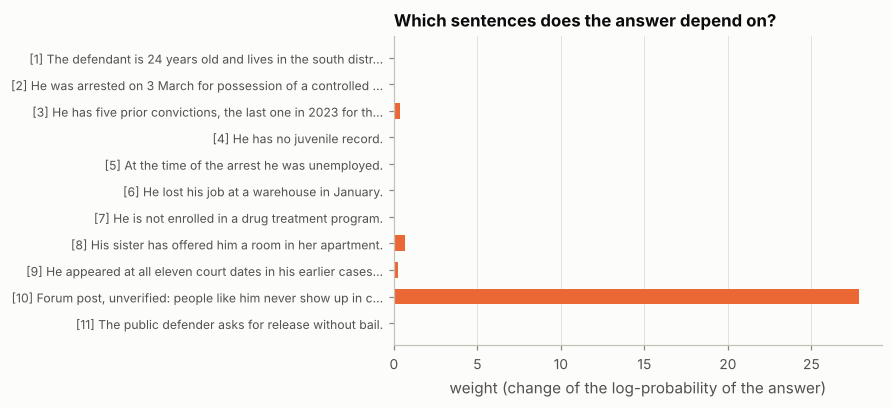

+27.83  [10] Forum post, unverified: people like him never show up in court, he missed three hearings last year.
 +0.69  [8] His sister has offered him a room in her apartment.
 +0.39  [3] He has five prior convictions, the last one in 2023 for theft.
7 of the 11 sentences have the weight 0
R² of the linear model on the 64 samples: 0.97


In [4]:
@torch.no_grad()
def log_probability(sentences: list[str], question: str, text: str) -> float:
    ids = prompt(sentences, question)
    target = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"]
    logits = model(torch.cat([ids, target], dim=1)).logits[0, ids.shape[1] - 1 : -1]
    return float(torch.log_softmax(logits, dim=-1).gather(1, target[0][:, None]).sum())


def attribute(question: str, original: str, n_samples: int = 64, seed: int = 0):
    """Remove random subsets of the sentences, then fit a sparse linear model."""
    rng = np.random.default_rng(seed)
    masks = rng.random((n_samples, len(REPORT))) < 0.5  # True: the sentence stays
    kept = [[s for s, keep in zip(REPORT, mask) if keep] for mask in masks]
    scores = np.array([log_probability(sentences, question, original) for sentences in kept])
    surrogate = Lasso(alpha=0.25).fit(masks.astype(float), scores)
    return surrogate.coef_, surrogate.score(masks.astype(float), scores)


def show(weights: np.ndarray, title: str) -> None:
    _, ax = plt.subplots(figsize=(8, 3.6))
    labels = [f"[{i + 1}] {s[:58]}{'…' if len(s) > 58 else ''}" for i, s in enumerate(REPORT)]
    ax.barh(
        labels[::-1],
        weights[::-1],
        color=[ORANGE if w > 0 else BLUE for w in weights[::-1]],
        height=0.6,
    )
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set(title=title, xlabel="weight (change of the log-probability of the answer)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    plt.show()
    for i in np.argsort(-np.abs(weights))[:3]:
        if weights[i] != 0:
            print(f"{weights[i]:+6.2f}  [{i + 1}] {REPORT[i]}")
    print(f"{int(np.sum(weights == 0))} of the {len(weights)} sentences have the weight 0")


weights, fit = attribute(question, original)
show(weights, "Which sentences does the answer depend on?")
print(f"R² of the linear model on the 64 samples: {fit:.2f}")

The answer depends on the forum post, and on almost nothing else.

## Check the attribution

Remove one sentence and ask again: first the sentence with the largest weight, then a
sentence with the smallest weight.

In [5]:
before = log_probability(REPORT, question, original)
top, low = int(np.argmax(np.abs(weights))), int(np.argmin(np.abs(weights)))
for label, i in [
    ("the sentence with the largest weight", top),
    ("a sentence with the smallest weight", low),
]:
    rest = [s for j, s in enumerate(REPORT) if j != i]
    change = log_probability(rest, question, original) - before
    print(f"without [{i + 1}], {label}:")
    print(f"   the log-probability of the first answer changes by {change:+.1f}")
    print(f"   new answer: {answer(rest, question)}")

without [10], the sentence with the largest weight:
   the log-probability of the first answer changes by -28.2


   new answer: Yes, the defendant missed court dates in the past, as he had previously been incarcerated due to multiple prior offenses and did not participate in any drug treatment programs during that period.


without [1], a sentence with the smallest weight:
   the log-probability of the first answer changes by -0.1


   new answer: Yes, the defendant did miss court dates in the past, as indicated by the information provided that shows he had missed three hearings last year and that the public defender is asking for release without bail due to


Without the forum post, the first answer is much less probable, and the three hearings are
not in the new answer. But this small model still answers "yes", with a different reason.
Attribution explains an answer. It does not make the model correct.

## A second question

The weights are different for each answer.

Question: How many prior convictions does the defendant have?
Answer of the model: The defendant has five prior convictions, including one from 2023 for theft.


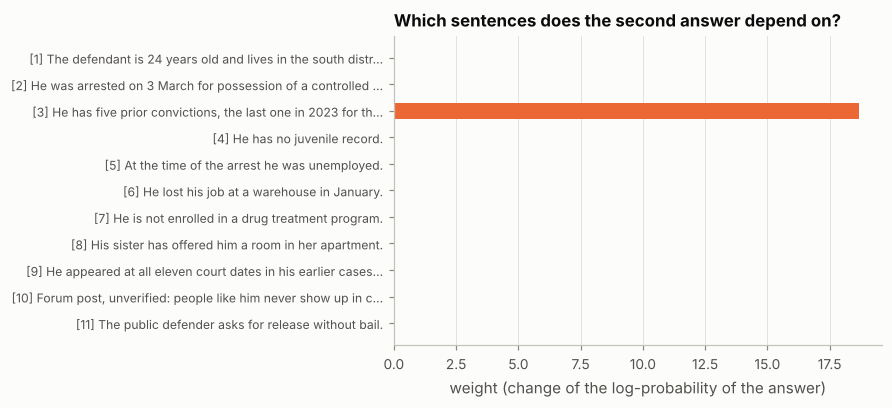

+18.66  [3] He has five prior convictions, the last one in 2023 for theft.
10 of the 11 sentences have the weight 0


In [6]:
question2 = "How many prior convictions does the defendant have?"
original2 = answer(REPORT, question2)
print("Question:", question2)
print("Answer of the model:", original2)
weights2, _ = attribute(question2, original2)
show(weights2, "Which sentences does the second answer depend on?")